# Proyecto ML — Detección de ataques IoT con CICIoT2023

**Autor:** Carlos Mateo Velastegui

## 1. Introducción

El Internet de las Cosas (IoT) ha crecido de forma acelerada en los últimos años. A finales de 2024 había alrededor de 18.5 mil millones de dispositivos IoT conectados en el mundo, y se estima que esta cifra llegará a 39 mil millones en 2030 [1]. Cámaras, sensores, asistentes de voz y enchufes inteligentes forman hoy parte de hogares, industrias y servicios críticos. Sin embargo, muchos de estos dispositivos tienen recursos limitados, contraseñas por defecto y pocas actualizaciones de seguridad, lo que los convierte en un blanco atractivo para los atacantes.

Un ejemplo claro de este riesgo es la botnet Mirai, que en 2016 llegó a infectar alrededor de 600,000 dispositivos IoT y los utilizó para lanzar ataques de denegación de servicio distribuida (DDoS) de gran escala contra objetivos de alto perfil [2]. Casos como este muestran que no basta con proteger cada dispositivo de forma individual: también es necesario monitorear el tráfico de red y detectar automáticamente cuándo un flujo corresponde a un ataque. Los sistemas de detección de intrusos basados en aprendizaje automático (*machine learning*) son una alternativa prometedora, porque pueden aprender patrones de tráfico malicioso a partir de datos etiquetados.

Para este proyecto se utiliza el dataset CICIoT2023, desarrollado por el Canadian Institute for Cybersecurity. Este dataset fue generado ejecutando 34 ataques sobre una topología de 105 dispositivos IoT reales, y los ataques se agrupan en siete categorías: DDoS, DoS, Recon, Web-based, fuerza bruta, spoofing y Mirai [3]. Cada registro describe un flujo de red mediante 46 características numéricas, como la duración del flujo, el tamaño de los paquetes, las banderas TCP y el protocolo utilizado. En este trabajo, las 33 etiquetas originales se agrupan en ocho clases (las siete categorías de ataque más el tráfico benigno), lo que define un problema de clasificación multiclase.

## 2. Configuración

In [35]:
# Código desarrollado con ayuda de Claude (Anthropic). Prompt usado: ver la sección 'Uso de IA' al final del notebook.
# --- Dataset CICIoT2023 ---
# "drive":   lee train/validation/test desde tu Google Drive (opción por defecto)
# "muestra": usa el CSV pequeño CICIoT2023_muestra_2500_por_clase.csv (más rápido)
# "kaggle":  descarga el dataset completo con kagglehub
DATA_SOURCE = "drive"
DRIVE_DIR = "/content/drive/MyDrive/MACHINE LEARNING TESIS/CICIOT23"
SAMPLE_CSV = "CICIoT2023_muestra_2500_por_clase.csv"   # o p. ej. "/content/drive/MyDrive/CICIoT2023_muestra_2500_por_clase.csv"
KAGGLE_DATASET = "himadri07/ciciot2023"
GROUP_CLASSES = True    # True => agrupa las ~34 etiquetas originales en 8 clases (Benign, DDoS, DoS, Mirai, ...)

RANDOM_STATE = 42
ROWS_PER_CLASS = 2500   # máximo de registros por clase (8 clases => ~20,000). Baja a 1000 si todo tarda mucho
MAX_FILES = 60          # máximo de archivos CSV a leer (el dataset completo es muy grande)
TEST_SIZE = 0.20        # 20% se guarda como test final y NO se toca hasta el final

# Repeated k-fold para OPTIMIZAR hiperparámetros (más barato)
TUNE_SPLITS, TUNE_REPEATS = 5, 2
# Repeated k-fold para la COMPARACIÓN estadística (rúbrica: 10x10; si es muy lento, 5x2)
CMP_SPLITS, CMP_REPEATS = 10, 10
FAST_MODE = False       # True => usa 5 folds x 2 repeticiones en la comparación

SCORING = "f1_macro"    # F1 macro: trata igual a todas las clases
USE_OPTUNA = True      # Opcional (extra): True para correr la sección de Optuna

In [12]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     GridSearchCV, validation_curve, learning_curve, cross_val_score)
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
from sklearn.manifold import TSNE
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

if FAST_MODE: CMP_SPLITS, CMP_REPEATS = 5, 2

## 2.1 Carga de datos

El dataset completo de CICIoT2023 tiene millones de registros (~2.3 GB), demasiado para un proyecto en Colab. Por eso se trabaja con una **muestra de como máximo 2,500 registros por clase**. Así las clases poco comunes (ataques web, fuerza bruta) también tienen suficientes ejemplos.
Las ~34 etiquetas originales se agrupan en 8 clases (`GROUP_CLASSES = True`).

* `DATA_SOURCE = "drive"`: lee train/validation/test desde Google Drive y arma la muestra aquí (tarda unos minutos porque lee ~2.3 GB).
* `DATA_SOURCE = "muestra"`: lee un CSV de muestra ya preparado (19,650 filas).
* `DATA_SOURCE = "kaggle"`: descarga todo con `kagglehub` y arma la muestra aquí.

In [10]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if DATA_SOURCE == "drive" and not IN_COLAB:
    print("No se detectó Google Colab: se usa la muestra local", SAMPLE_CSV)
    DATA_SOURCE = "muestra"

if DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    files = sorted(Path(DRIVE_DIR).rglob("*.csv"))
    files = [f for f in files if "muestra" not in f.name]
elif DATA_SOURCE == "kaggle":
    import kagglehub
    path = kagglehub.dataset_download(KAGGLE_DATASET)
    print("Path to dataset files:", path)
    files = sorted(p for p in Path(path).rglob("*") if p.suffix.lower() in (".csv", ".parquet"))
else:
    files = [Path(SAMPLE_CSV)]
print("Archivos:", len(files)); print([f.name for f in files[:5]])

Mounted at /content/drive
Archivos: 3
['test.csv', 'train.csv', 'validation.csv']


In [13]:
def find_label_col(columns):
    for c in columns:
        if c.strip().lower() in ("label", "labels", "class", "attack"):
            return c
    return columns[-1]          # en CICIoT2023 la etiqueta es la última columna

def group_label(lbl):
    """Agrupa las etiquetas originales de CICIoT2023 en 8 clases."""
    l = str(lbl).lower()
    if "benign" in l: return "Benign"
    if l.startswith("ddos"): return "DDoS"
    if l.startswith("dos"): return "DoS"
    if "mirai" in l: return "Mirai"
    if "recon" in l or "vulnerabilityscan" in l: return "Recon"
    if "spoof" in l: return "Spoofing"
    if "bruteforce" in l: return "BruteForce"
    if any(w in l for w in ["sql", "xss", "commandinjection", "backdoor", "browserhijacking", "uploading"]):
        return "Web-based"
    return str(lbl)

assert files, f"No se encontraron CSV. Revisa la ruta: {DRIVE_DIR}"
pools, LABEL_COL = {}, None
for i, f in enumerate(files[:MAX_FILES]):
    chunks = [pd.read_parquet(f)] if f.suffix.lower() == ".parquet" else pd.read_csv(f, chunksize=200_000)
    for chunk in chunks:
        chunk = chunk.drop(columns=["attack_class"], errors="ignore")
        if LABEL_COL is None: LABEL_COL = find_label_col(list(chunk.columns))
        chunk["target"] = chunk[LABEL_COL].map(group_label) if GROUP_CLASSES else chunk[LABEL_COL].astype(str)
        for cls, part in chunk.groupby("target"):
            have = sum(len(x) for x in pools.get(cls, []))
            if have < ROWS_PER_CLASS:
                pools.setdefault(cls, []).append(part.sample(min(len(part), ROWS_PER_CLASS - have),
                                                             random_state=RANDOM_STATE))
    if (i + 1) % 10 == 0: print(f"{i+1} archivos leídos...")

df = pd.concat([pd.concat(v) for v in pools.values()], ignore_index=True)
df = df.drop(columns=[LABEL_COL]).rename(columns={"target": "attack_class"})
LABEL_COL = "attack_class"

# Clases con muy pocos ejemplos no se pueden usar en 10-fold estratificado
counts = df[LABEL_COL].value_counts()
too_small = counts[counts < 3 * CMP_SPLITS].index.tolist()
if too_small:
    print("Se eliminan clases con muy pocos registros:", too_small)
    df = df[~df[LABEL_COL].isin(too_small)].reset_index(drop=True)

FEATURES = [c for c in df.select_dtypes(include="number").columns if c != LABEL_COL]
df = df[FEATURES + [LABEL_COL]]
print("Filas:", len(df), "| Features:", len(FEATURES))
display(df[LABEL_COL].value_counts())
df.head()

Filas: 19650 | Features: 46


,count
attack_class,
Benign,2500
DDoS,2500
DoS,2500
Mirai,2500
Spoofing,2500
Recon,2500
Web-based,2500
BruteForce,2150


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,attack_class
0,51.127261,2342124.0,9.3,136.8,44.346683,44.346683,0.0,0.0,0.0,0.0,...,485.041530,356.8,1.665234e+08,13.5,49.228792,684.399574,3.011574e+05,0.8,244.6,Benign
1,4.272719,383435.0,6.0,150.3,79.620080,79.620080,0.0,0.0,0.0,0.0,...,1037.737963,837.3,1.665237e+08,13.5,53.049998,1467.084497,1.077532e+06,1.0,244.6,Benign
2,26.525843,54670.2,4.2,42.7,14.471363,14.471363,0.0,0.0,0.0,0.0,...,38.000193,91.2,2.683091e-02,5.5,14.179944,53.740389,1.607428e+03,0.9,38.5,Benign
3,26.239910,465754.7,6.0,81.0,47.605869,47.605869,0.0,0.0,0.0,0.0,...,539.480423,1233.0,6.750607e-03,5.5,25.507656,762.940531,6.555500e+05,0.8,38.5,Benign
4,32.179701,899231.5,17.0,60.0,25.124532,25.124532,0.0,0.0,0.0,0.0,...,207.059294,1308.4,2.533913e-04,5.5,50.983641,292.826061,6.218838e+04,0.7,38.5,Benign


## 3. EDA — Exploratory Data Analysis

In [14]:
# 3.1 Tipos de datos y estadísticas básicas
display(df.describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
flow_duration,19650.0,1.852210e+02,2.059299e+03,0.000,0.034,3.797000e+00,4.506900e+01,9.943576e+04
Header_Length,19650.0,4.348381e+05,1.137751e+06,0.000,108.000,1.110794e+04,1.520146e+05,9.799668e+06
Protocol Type,19650.0,1.180700e+01,1.112300e+01,0.600,6.000,7.100000e+00,1.370000e+01,4.700000e+01
Duration,19650.0,8.715100e+01,3.954400e+01,2.000,64.000,6.568000e+01,9.940000e+01,2.550000e+02
Rate,19650.0,5.098836e+03,7.984765e+04,0.000,4.789,3.067600e+01,1.216700e+02,5.242880e+06
Srate,19650.0,5.098836e+03,7.984765e+04,0.000,4.789,3.067600e+01,1.216700e+02,5.242880e+06
Drate,19650.0,0.000000e+00,0.000000e+00,0.000,0.000,0.000000e+00,0.000000e+00,0.000000e+00
fin_flag_number,19650.0,1.500000e-02,1.200000e-01,0.000,0.000,0.000000e+00,0.000000e+00,1.000000e+00
syn_flag_number,19650.0,7.900000e-02,2.710000e-01,0.000,0.000,0.000000e+00,0.000000e+00,1.000000e+00
rst_flag_number,19650.0,2.800000e-02,1.660000e-01,0.000,0.000,0.000000e+00,0.000000e+00,1.000000e+00


In [15]:
# 3.2 Valores faltantes e infinitos (CICIoT2023 tiene 'inf' en columnas como Rate)
X_num = df[FEATURES]
quality = pd.DataFrame({"faltantes": X_num.isna().sum(),
                        "infinitos": np.isinf(X_num).sum(),
                        "valores_unicos": X_num.nunique()})
display(quality[(quality.faltantes > 0) | (quality.infinitos > 0) | (quality.valores_unicos <= 1)])
print("Columnas constantes:", list(quality.index[quality.valores_unicos <= 1]))
print("Filas duplicadas:", df.duplicated().sum())

# Los infinitos se convierten a NaN; el imputer del pipeline los rellena después
df[FEATURES] = df[FEATURES].replace([np.inf, -np.inf], np.nan)
# Eliminar columnas constantes (no aportan información al modelo)
const_cols = quality.index[quality.valores_unicos <= 1].tolist()
df = df.drop(columns=const_cols)
FEATURES = [c for c in FEATURES if c not in const_cols]
print("Columnas constantes eliminadas:", const_cols)

# Eliminar filas duplicadas (evitar redundancia)
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Filas duplicadas eliminadas: {n_antes - len(df)} | Filas restantes: {len(df)}")

,faltantes,infinitos,valores_unicos
Drate,0,0,1
ece_flag_number,0,0,1
cwr_flag_number,0,0,1
Telnet,0,0,1
SMTP,0,0,1
IRC,0,0,1
DHCP,0,0,1


Columnas constantes: ['Drate', 'ece_flag_number', 'cwr_flag_number', 'Telnet', 'SMTP', 'IRC', 'DHCP']
Filas duplicadas: 147
Columnas constantes eliminadas: ['Drate', 'ece_flag_number', 'cwr_flag_number', 'Telnet', 'SMTP', 'IRC', 'DHCP']
Filas duplicadas eliminadas: 147 | Filas restantes: 19503


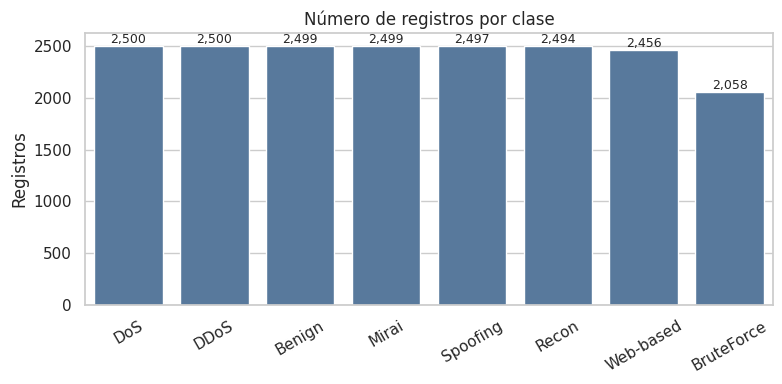

,proporción
attack_class,
DoS,0.128
DDoS,0.128
Benign,0.128
Mirai,0.128
Spoofing,0.128
Recon,0.128
Web-based,0.126
BruteForce,0.106


In [16]:
# 3.3 Distribución de clases (¿hay desbalance?)
counts = df[LABEL_COL].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#4C78A8")
ax.set_title("Número de registros por clase"); ax.set_ylabel("Registros"); ax.set_xlabel("")
for i, v in enumerate(counts.values): ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=30); plt.tight_layout(); plt.show()
display((counts / counts.sum()).round(3).rename("proporción"))

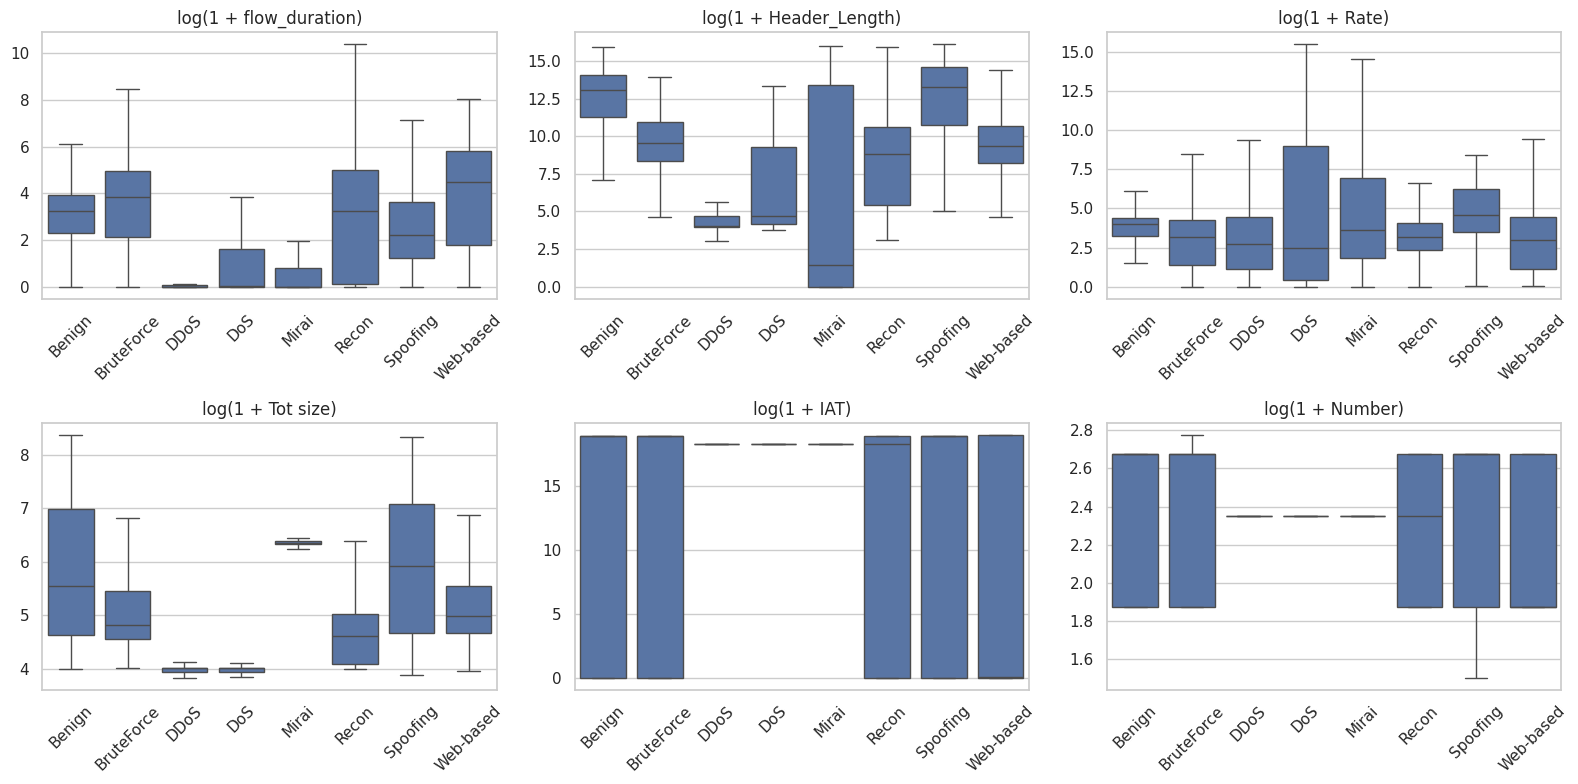

In [17]:
# 3.4 Distribución de algunas features por clase (escala log porque los rangos son muy grandes)
some = [c for c in ["flow_duration", "Header_Length", "Rate", "Tot size", "IAT", "Number"] if c in FEATURES][:6] \
       or FEATURES[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), some):
    sns.boxplot(data=df, x=LABEL_COL, y=np.log1p(df[col].clip(lower=0)), ax=ax, showfliers=False)
    ax.set_title(f"log(1 + {col})"); ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

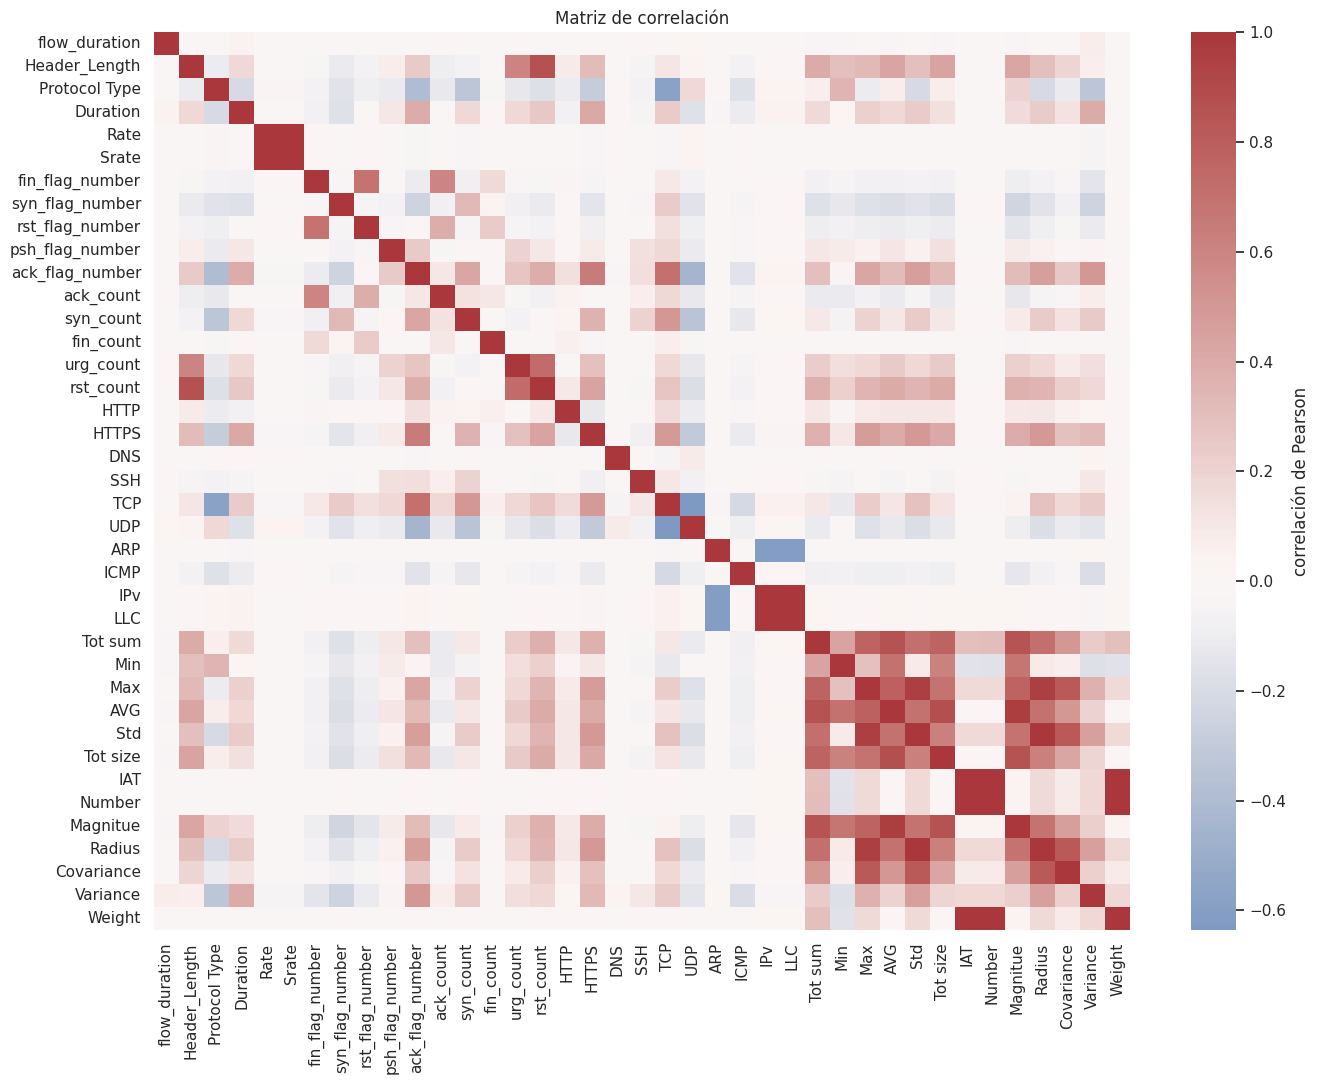

Pares con |correlación| > 0.95:


Rate    Srate       1.000000
IPv     LLC         1.000000
Std     Radius      0.999933
Number  Weight      0.999931
IAT     Weight      0.999428
        Number      0.999089
AVG     Magnitue    0.963289
Max     Std         0.955160
        Radius      0.955075
dtype: float64

Features eliminadas por alta correlación: ['Srate', 'LLC', 'Std', 'Number', 'Magnitue', 'Radius', 'Weight']
Features que quedan: 32


In [18]:
# 3.5 Correlación entre features (¿hay variables redundantes?)
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="vlag", center=0, ax=ax, cbar_kws={"label": "correlación de Pearson"})
ax.set_title("Matriz de correlación"); plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("Pares con |correlación| > 0.95:")
display(upper[upper.abs() > 0.95].sort_values(key=abs, ascending=False).head(15))
# De cada par con |correlación| > 0.95 se conserva solo una feature
upper_matrix = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
corr_drop = [c for c in upper_matrix.columns if (upper_matrix[c].abs() > 0.95).any()]
df = df.drop(columns=corr_drop)
FEATURES = [c for c in FEATURES if c not in corr_drop]
print("Features eliminadas por alta correlación:", corr_drop)
print("Features que quedan:", len(FEATURES))

**Conclusiones del EDA:**

En primer lugar, se encontraron las siguientes columnas con datos constantes: 'Drate', 'ece_flag_number', 'cwr_flag_number', 'Telnet', 'SMTP', 'IRC' y 'DHCP', además de 147 filas duplicadas las cuales se eliminaron para no generar redundancia. Las siguientes características (*features*) presentan una desviación estándar alta:

* **Por valores atípicos (*outliers*):** `Header_Length`, `Covariance`, `Rate`/`Srate` y `flow_duration` tienen una desviación estándar mucho más grande que la mediana. La mayoría de los valores son pequeños, pero unos pocos son extremadamente grandes. Por ejemplo, `Rate` tiene una mediana de 30 y un máximo de más de 3 millones.

* **Por escala:** `IAT` tiene una desviación alta simplemente porque todos sus valores son altos, por lo que debemos escalarlos.

Se encontraron 9 pares de características con correlaciones mayores al 95%. El dataset original estaba muy desbalanceado, por lo que se tomó una muestra de 2,500 registros por clase para evitar el sesgo del modelo hacia la clase predominante (DDoS).

En función de los hallazgos, se decide excluir las columnas con datos constantes, eliminar las filas repetidas y reemplazar los valores infinitos por valores nulos (NaN), que se corregirán posteriormente en el pipeline mediante la mediana. No se eliminarán los valores atípicos, ya que pueden representar los datos reales de los ataques, y se escalarán las características con valores altos en comparación con el resto. En el caso de las correlaciones, se trabajará únicamente con una de las 2 o 3 características indicadas en el gráfico 3.5.

## 4. Extracción de características (*Feature Extraction*)

No se realiza extracción de características, ya que el dataset utilizado es estructurado: cada registro de CICIoT2023 ya contiene 46 características numéricas extraídas de los flujos de red [3]. Este paso aplica principalmente a conjuntos de datos no estructurados, como imágenes o texto, donde se suele utilizar aprendizaje por transferencia (*transfer learning*).

## 5. Separación train / test

In [19]:
X = df[FEATURES]; y = df[LABEL_COL].astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (15602, 32) | Test: (3901, 32)


## 6. Pipelines y selección de características (*Feature Selection*) de tipo filtro

Cada modelo se estructura como un `Pipeline` de scikit-learn: **imputar → escalar → seleccionar características (filtro) → clasificador**.
Al estar todo contenido dentro del pipeline, en cada fold el imputer, el scaler y el selector se ajustan **solo con los datos de entrenamiento de ese fold**, evitando la fuga de información (*data leakage*).

El selector es `SelectKBest` (método de filtro): puntúa cada característica por separado frente a la etiqueta y conserva las `k` mejores. El valor de `k` también es un hiperparámetro que se optimiza.

Técnicas a comparar:
* **Random Forest** (ensamble de árboles, no lineal)
* **Regresión Logística** (modelo lineal)

In [20]:
def make_pipeline(model):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("select", SelectKBest(score_func=f_classif)),
        ("model", model),
    ])

pipe_rf = make_pipeline(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE))
pipe_lr = make_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000))
pipe_rf

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('select', SelectKBest()),
                ('model',
                 RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                        random_state=42))])

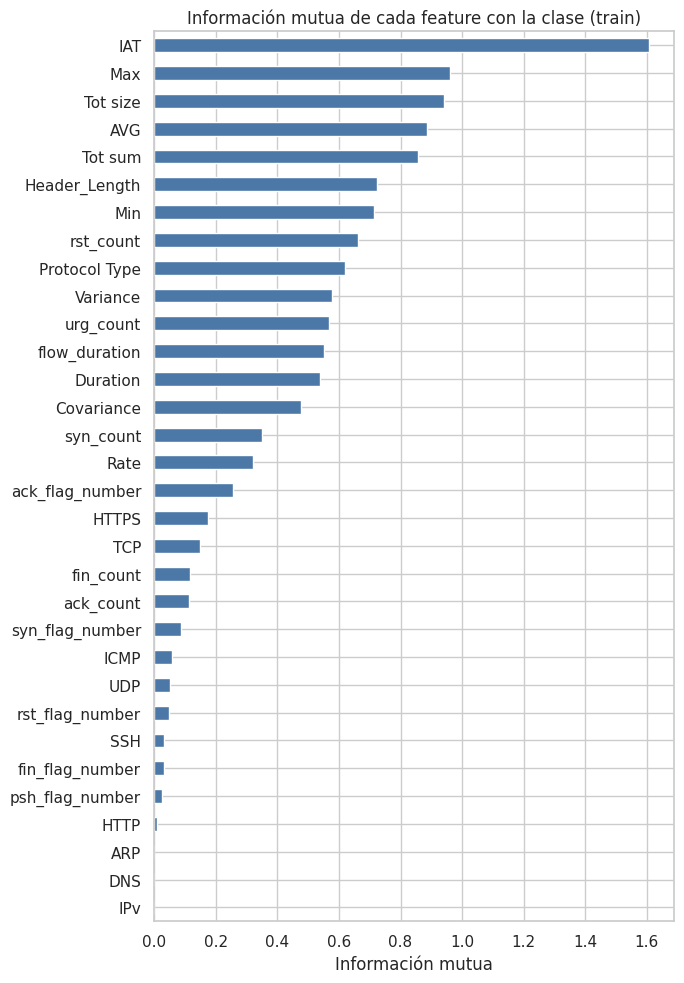

In [21]:
# Ranking del filtro (información mutua) solo con train, para entender qué features importan
Xi = SimpleImputer(strategy="median").fit_transform(X_train)
mi = pd.Series(mutual_info_classif(Xi, y_train, random_state=RANDOM_STATE), index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 10))
mi.plot.barh(ax=ax, color="#4C78A8"); ax.set_title("Información mutua de cada feature con la clase (train)")
ax.set_xlabel("Información mutua"); plt.tight_layout(); plt.show()

## 7. Optimización de hiperparámetros con validación cruzada repetida y estratificada (Repeated K-Fold CV)

Se utiliza `GridSearchCV` con `RepeatedStratifiedKFold` únicamente sobre el conjunto de **entrenamiento (train)**, manteniendo a salvo el conjunto de prueba (test). La estratificación asegura que se conserve la proporción original de las clases en cada partición (*fold*).

In [22]:
n_feat = len(FEATURES)
K_GRID = sorted({k for k in [10, 20, 30, n_feat] if k <= n_feat})
tune_cv = RepeatedStratifiedKFold(n_splits=TUNE_SPLITS, n_repeats=TUNE_REPEATS, random_state=RANDOM_STATE)

grid_rf = {"select__k": K_GRID,
           "model__n_estimators": [100, 300],
           "model__max_depth": [10, 20, None],
           "model__min_samples_leaf": [1, 3]}
grid_lr = {"select__k": K_GRID,
           "model__C": [0.01, 0.1, 1, 10, 100]}

search_rf = GridSearchCV(pipe_rf, grid_rf, cv=tune_cv, scoring=SCORING, n_jobs=-1, verbose=1).fit(X_train, y_train)
search_lr = GridSearchCV(pipe_lr, grid_lr, cv=tune_cv, scoring=SCORING, n_jobs=-1, verbose=1).fit(X_train, y_train)

for name, s in [("Random Forest", search_rf), ("Regresión Logística", search_lr)]:
    print(f"{name}: mejor {SCORING} en CV = {s.best_score_:.4f}")
    print("   mejores hiperparámetros:", s.best_params_)

Fitting 10 folds for each of 48 candidates, totalling 480 fits
Fitting 10 folds for each of 20 candidates, totalling 200 fits
Random Forest: mejor f1_macro en CV = 0.8800
   mejores hiperparámetros: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 300, 'select__k': 32}
Regresión Logística: mejor f1_macro en CV = 0.6479
   mejores hiperparámetros: {'model__C': 100, 'select__k': 32}


In [23]:
# Tabla con todas las combinaciones probadas (Random Forest)
res = pd.DataFrame(search_rf.cv_results_)
cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
display(res[cols].sort_values("rank_test_score").head(10))

,param_model__max_depth,param_model__min_samples_leaf,param_model__n_estimators,param_select__k,mean_test_score,std_test_score,rank_test_score
39,None,1,300,32,0.879958,0.004681,1
23,20,1,300,32,0.878004,0.005843,2
35,None,1,100,32,0.876753,0.004456,3
19,20,1,100,32,0.876631,0.006028,4
47,None,3,300,32,0.874703,0.004282,5
31,20,3,300,32,0.873187,0.003112,6
27,20,3,100,32,0.872141,0.003344,7
43,None,3,100,32,0.871248,0.004059,8
7,10,1,300,32,0.837478,0.004764,9
3,10,1,100,32,0.835925,0.006539,10


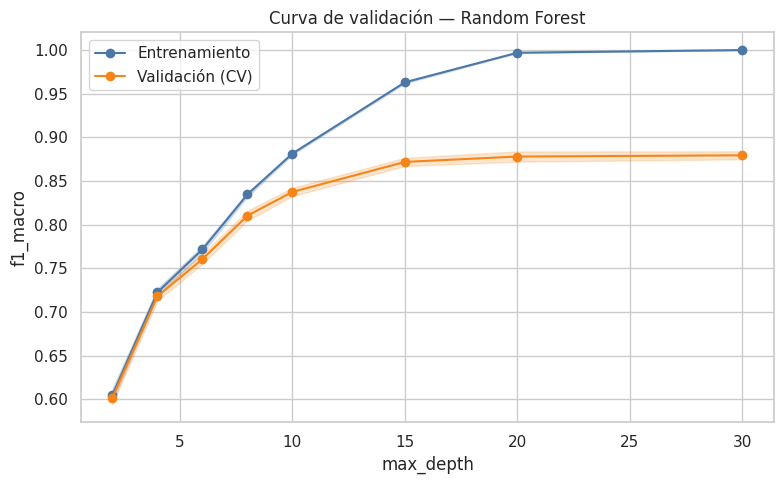

In [24]:
# Gráfica de optimización de un hiperparámetro: max_depth del Random Forest
# (los demás hiperparámetros se fijan en su mejor valor)
best_rf = search_rf.best_estimator_
depths = [2, 4, 6, 8, 10, 15, 20, 30]
tr_s, va_s = validation_curve(best_rf, X_train, y_train, param_name="model__max_depth",
                              param_range=depths, cv=tune_cv, scoring=SCORING, n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 5))
for s, lab, col in [(tr_s, "Entrenamiento", "#4C78A8"), (va_s, "Validación (CV)", "#F58518")]:
    m, sd = s.mean(1), s.std(1)
    ax.plot(depths, m, "o-", label=lab, color=col); ax.fill_between(depths, m - sd, m + sd, alpha=.2, color=col)
ax.set_xlabel("max_depth"); ax.set_ylabel(SCORING); ax.set_title("Curva de validación — Random Forest")
ax.legend(); plt.tight_layout(); plt.show()

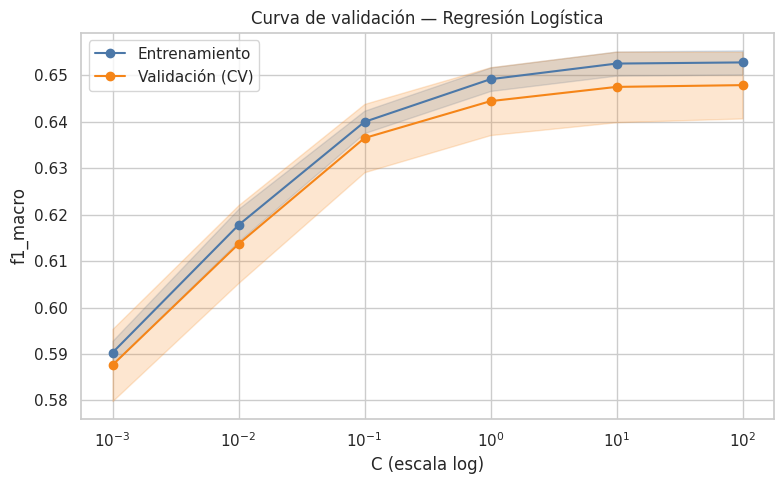

In [25]:
# Mismo tipo de gráfica para C de la Regresión Logística
best_lr = search_lr.best_estimator_
Cs = [0.001, 0.01, 0.1, 1, 10, 100]
tr_s, va_s = validation_curve(best_lr, X_train, y_train, param_name="model__C",
                              param_range=Cs, cv=tune_cv, scoring=SCORING, n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 5))
for s, lab, col in [(tr_s, "Entrenamiento", "#4C78A8"), (va_s, "Validación (CV)", "#F58518")]:
    m, sd = s.mean(1), s.std(1)
    ax.plot(Cs, m, "o-", label=lab, color=col); ax.fill_between(Cs, m - sd, m + sd, alpha=.2, color=col)
ax.set_xscale("log"); ax.set_xlabel("C (escala log)"); ax.set_ylabel(SCORING)
ax.set_title("Curva de validación — Regresión Logística"); ax.legend(); plt.tight_layout(); plt.show()

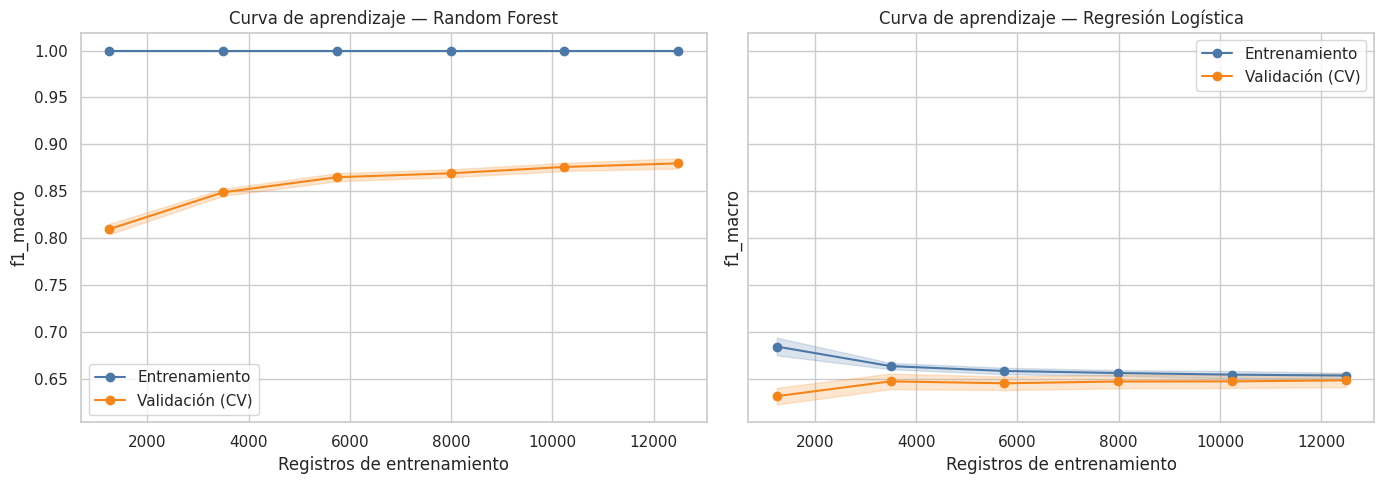

In [26]:
# Curva de aprendizaje: ¿mejora el modelo con más datos?
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, est) in zip(axes, [("Random Forest", best_rf), ("Regresión Logística", best_lr)]):
    sizes, tr_s, va_s = learning_curve(est, X_train, y_train, cv=tune_cv, scoring=SCORING,
                                       train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1)
    for s, lab, col in [(tr_s, "Entrenamiento", "#4C78A8"), (va_s, "Validación (CV)", "#F58518")]:
        m, sd = s.mean(1), s.std(1)
        ax.plot(sizes, m, "o-", label=lab, color=col); ax.fill_between(sizes, m - sd, m + sd, alpha=.2, color=col)
    ax.set_title(f"Curva de aprendizaje — {name}"); ax.set_xlabel("Registros de entrenamiento"); ax.set_ylabel(SCORING)
    ax.legend()
plt.tight_layout(); plt.show()

**Análisis de la optimización:**

La optimización con validación cruzada estratificada repetida (5 folds × 2 repeticiones) seleccionó para Random Forest los parámetros `n_estimators = 300`, `max_depth = None` (sin límite de profundidad), `min_samples_leaf = 1` y `k = 32`, alcanzando un F1-macro de 0.880 en validación. Para la Regresión Logística, el mejor valor fue `C = 100` con `k = 32`, obteniendo un F1-macro de 0.648. En ambos casos, el filtro conservó las 32 características, lo que indica que, tras eliminar las columnas constantes y redundantes en el EDA, todas las características restantes aportan información útil.

En la curva de validación de Random Forest, el F1 de validación sube de 0.60 (`max_depth = 2`) a 0.88 (`max_depth = 20`) y luego se estabiliza, mientras que el F1 de entrenamiento llega a 1.0. A partir de `max_depth ≈ 10` se abre una brecha entre ambas curvas, lo que muestra cierto sobreajuste (*overfitting*); sin embargo, el desempeño en validación no empeora, por lo que una mayor profundidad sigue siendo la mejor opción. En la Regresión Logística, el F1 sube de 0.59 (`C = 0.001`) a 0.65 (`C = 100`) y las curvas de entrenamiento y validación están casi superpuestas, lo que indica que el modelo no sobreajusta, sino que es demasiado simple (sufre de subajuste o *underfitting*) para separar adecuadamente las clases.

La curva de aprendizaje de Random Forest muestra que el F1 de validación sigue aumentando a medida que se incorporan más datos (de 0.81 a 0.88), por lo que el modelo podría beneficiarse de una muestra mayor. En cambio, la Regresión Logística se estanca en ≈0.65 a partir de los 3,500 registros: agregar más datos no mejorará su rendimiento.

### 7.1 Opcional (extra): Optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 17.4 MB/s eta 0:00:00
Mejor F1 macro (Optuna): 0.878
{'select__k': 32, 'model__n_estimators': 150, 'model__max_depth': 23, 'model__min_samples_leaf': 1}


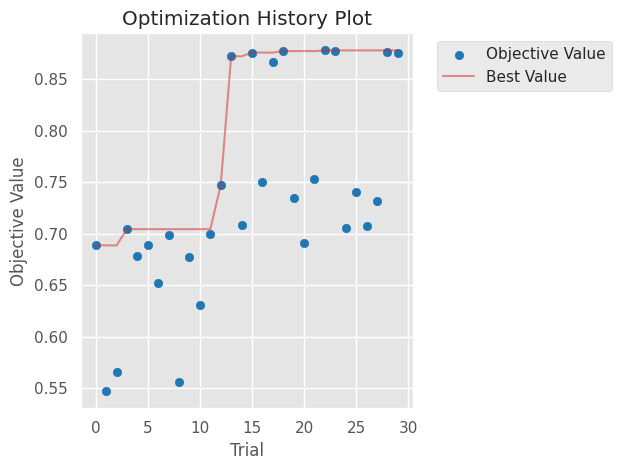

In [36]:
if USE_OPTUNA:
    try:
        import optuna
    except ImportError:
        %pip install -q optuna
        import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    def objective(trial):
        params = {"select__k": trial.suggest_int("select__k", 5, len(FEATURES)),
                  "model__n_estimators": trial.suggest_int("model__n_estimators", 50, 400, step=50),
                  "model__max_depth": trial.suggest_int("model__max_depth", 3, 30),
                  "model__min_samples_leaf": trial.suggest_int("model__min_samples_leaf", 1, 10)}
        est = clone(pipe_rf).set_params(**params)   # copia: no modifica pipe_rf
        return cross_val_score(est, X_train, y_train, cv=tune_cv, scoring=SCORING, n_jobs=-1).mean()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=30)
    print("Mejor F1 macro (Optuna):", round(study.best_value, 4)); print(study.best_params)
    optuna.visualization.matplotlib.plot_optimization_history(study); plt.show()
else:
    print("Optuna desactivado (USE_OPTUNA = False).")

## 8. Comparación estadística de las dos técnicas

Ambos modelos (con sus mejores hiperparámetros) se evalúan con **el mismo** objeto `RepeatedStratifiedKFold` (mismas particiones), de manera que cada fold genera un **par** de resultados comparables. Con 10 folds × 10 repeticiones se obtienen 100 pares de datos.

* **H₀ (Hipótesis Nula):** no existe diferencia en el F1-macro promedio entre Random Forest y Regresión Logística.
* **H₁ (Hipótesis Alternativa):** existe una diferencia estadísticamente significativa.
* Nivel de significancia establecido: α = 0.05.

Se aplican dos pruebas estadísticas sobre las diferencias pareadas:
1. **Prueba de rangos con signo de Wilcoxon** (no asume normalidad).
2. **Prueba t de Student pareada corregida de Nadeau y Bengio**: la prueba t convencional tiende a ser demasiado optimista con validación cruzada repetida debido a que las particiones comparten datos de entrenamiento; esta versión corrige la varianza para evitar falsos positivos.

In [29]:
cmp_cv = RepeatedStratifiedKFold(n_splits=CMP_SPLITS, n_repeats=CMP_REPEATS, random_state=RANDOM_STATE + 1)
scores_rf = cross_val_score(best_rf, X_train, y_train, cv=cmp_cv, scoring=SCORING, n_jobs=-1)
scores_lr = cross_val_score(best_lr, X_train, y_train, cv=cmp_cv, scoring=SCORING, n_jobs=-1)

summary = pd.DataFrame({"Random Forest": scores_rf, "Regresión Logística": scores_lr}).agg(["mean", "std", "min", "max"]).T
print(f"{CMP_REPEATS} repeticiones x {CMP_SPLITS} folds = {len(scores_rf)} pares"); display(summary.round(4))

10 repeticiones x 10 folds = 100 pares


,mean,std,min,max
Random Forest,0.8813,0.0075,0.8607,0.896
Regresión Logística,0.6479,0.0097,0.6258,0.677


In [30]:
diff = scores_rf - scores_lr
alpha = 0.05

# 1) Wilcoxon signed-rank
w_stat, w_p = stats.wilcoxon(scores_rf, scores_lr)

# 2) t-test pareado corregido (Nadeau & Bengio, 2003)
n = len(diff)
n_test_ratio = 1 / CMP_SPLITS                # tamaño test / tamaño train en cada fold
n_train_ratio = 1 - n_test_ratio
corrected_var = (1 / n + n_test_ratio / n_train_ratio) * diff.var(ddof=1)
t_stat = diff.mean() / np.sqrt(corrected_var)
t_p = 2 * stats.t.sf(abs(t_stat), df=n - 1)

# Normalidad de las diferencias (para saber si tiene sentido un t-test)
sh_stat, sh_p = stats.shapiro(diff)

results = pd.DataFrame([
    {"test": "Shapiro-Wilk (normalidad de diferencias)", "estadístico": sh_stat, "p_value": sh_p},
    {"test": "Wilcoxon signed-rank", "estadístico": w_stat, "p_value": w_p},
    {"test": "t-test pareado corregido (Nadeau-Bengio)", "estadístico": t_stat, "p_value": t_p},
])
results["¿rechaza H0? (α=0.05)"] = np.where(results.p_value < alpha, "Sí", "No")
results.loc[0, "¿rechaza H0? (α=0.05)"] = "— (solo verifica normalidad)"
display(results.round(6))
print(f"Diferencia media (RF − LR): {diff.mean():.4f}")

,test,estadístico,p_value,¿rechaza H0? (α=0.05)
0,Shapiro-Wilk (normalidad de diferencias),0.988783,0.567611,— (solo verifica normalidad)
1,Wilcoxon signed-rank,0.000000,0.000000,Sí
2,t-test pareado corregido (Nadeau-Bengio),64.414475,0.000000,Sí


Diferencia media (RF − LR): 0.2334


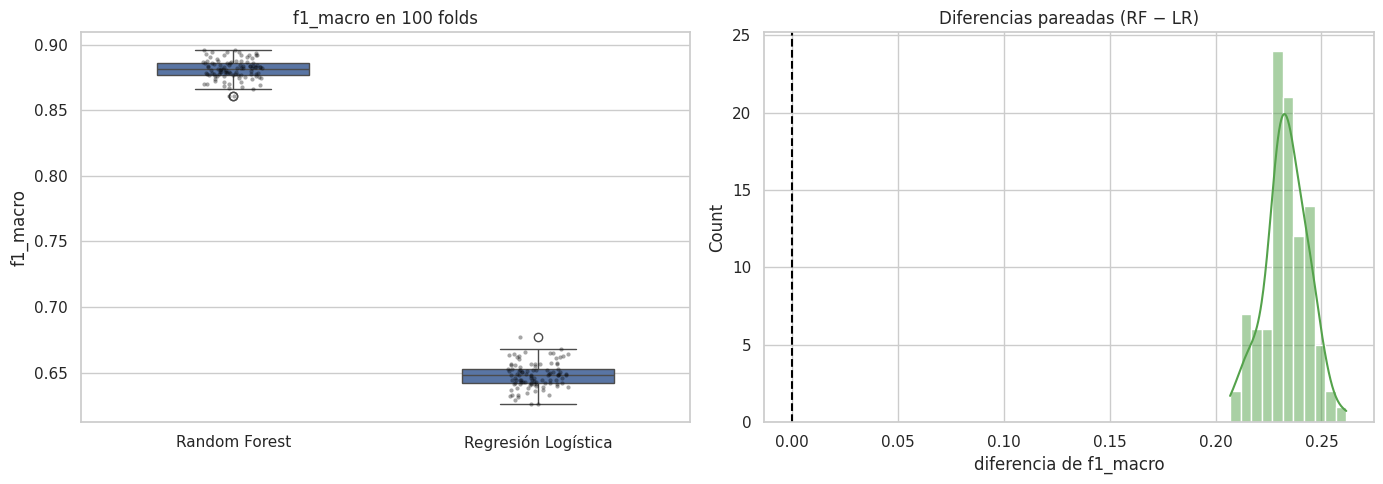

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
long = pd.DataFrame({"Random Forest": scores_rf, "Regresión Logística": scores_lr}).melt(var_name="modelo", value_name=SCORING)
sns.boxplot(data=long, x="modelo", y=SCORING, ax=axes[0], width=.5)
sns.stripplot(data=long, x="modelo", y=SCORING, ax=axes[0], color="black", alpha=.35, size=3)
axes[0].set_title(f"{SCORING} en {len(scores_rf)} folds"); axes[0].set_xlabel("")
sns.histplot(diff, kde=True, ax=axes[1], color="#54A24B")
axes[1].axvline(0, color="black", ls="--"); axes[1].set_title("Diferencias pareadas (RF − LR)")
axes[1].set_xlabel("diferencia de " + SCORING)
plt.tight_layout(); plt.show()

**Conclusión de las pruebas estadísticas:**

Mediante validación cruzada repetida (10 folds × 10 repeticiones = 100 pares de datos), Random Forest obtuvo un F1-macro promedio de 0.881 ± 0.008, frente al 0.648 ± 0.010 de la Regresión Logística, lo que representa una diferencia media de 0.233 a favor de Random Forest. La prueba de Shapiro-Wilk (p = 0.57) no rechaza la normalidad de las diferencias.

Tanto la prueba de Wilcoxon (p < 0.001) como la prueba t pareada corregida de Nadeau-Bengio (t = 64.4, p < 0.001) rechazan la hipótesis nula H₀ con un nivel de significancia de α = 0.05. Por lo tanto, existe una diferencia estadísticamente significativa que confirma la superioridad de Random Forest frente a la Regresión Logística.

Esta diferencia también es altamente relevante en la práctica: el peor resultado registrado por Random Forest (0.861) supera con creces al mejor resultado de la Regresión Logística (0.677), ganando en la totalidad de las 100 pruebas. Esto ocurre porque Random Forest es capaz de capturar relaciones complejas y no lineales entre las variables, mientras que la Regresión Logística se ve limitada a trazar fronteras de decisión puramente lineales.

## 9. Evaluación final en el test

===== Random Forest — F1 macro en test: 0.8902
              precision    recall  f1-score   support

      Benign      0.823     0.900     0.860       500
  BruteForce      0.844     0.816     0.830       412
        DDoS      0.998     0.998     0.998       500
         DoS      1.000     0.994     0.997       500
       Mirai      0.996     0.990     0.993       500
       Recon      0.884     0.752     0.813       499
    Spoofing      0.900     0.814     0.855       499
   Web-based      0.714     0.853     0.777       491

    accuracy                          0.891      3901
   macro avg      0.895     0.890     0.890      3901
weighted avg      0.896     0.891     0.892      3901



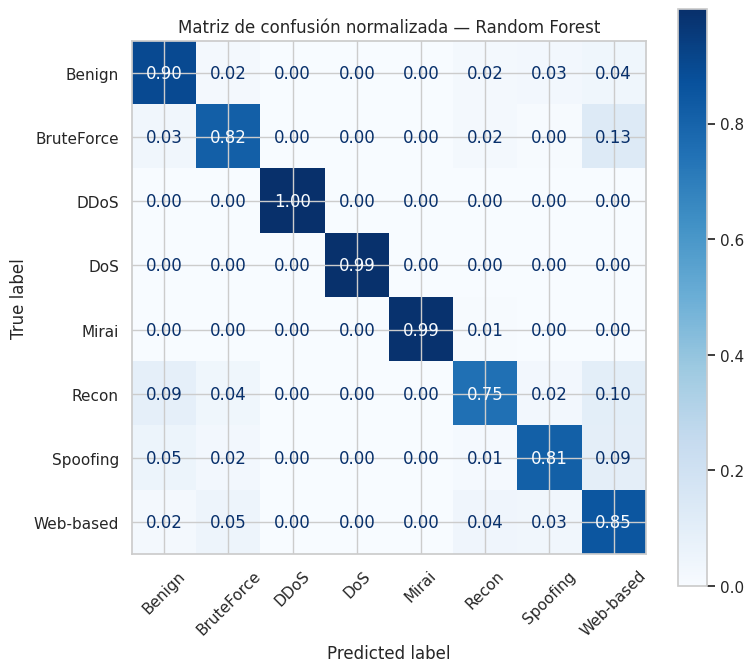

===== Regresión Logística — F1 macro en test: 0.6475
              precision    recall  f1-score   support

      Benign      0.618     0.680     0.648       500
  BruteForce      0.453     0.534     0.490       412
        DDoS      0.816     0.628     0.710       500
         DoS      0.687     0.872     0.768       500
       Mirai      0.978     0.988     0.983       500
       Recon      0.664     0.385     0.487       499
    Spoofing      0.689     0.565     0.621       499
   Web-based      0.417     0.546     0.473       491

    accuracy                          0.653      3901
   macro avg      0.665     0.650     0.648      3901
weighted avg      0.671     0.653     0.652      3901



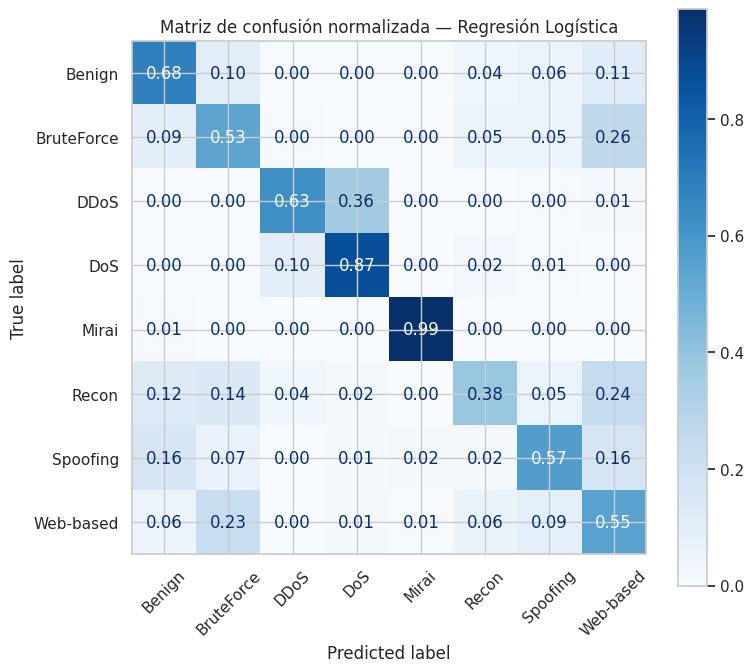

Features seleccionadas (RF): ['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'SSH', 'TCP', 'UDP', 'ARP', 'ICMP', 'IPv', 'Tot sum', 'Min', 'Max', 'AVG', 'Tot size', 'IAT', 'Covariance', 'Variance']


In [32]:
for name, est in [("Random Forest", best_rf), ("Regresión Logística", best_lr)]:
    est.fit(X_train, y_train)
    pred = est.predict(X_test)
    print(f"===== {name} — F1 macro en test: {f1_score(y_test, pred, average='macro'):.4f}")
    print(classification_report(y_test, pred, digits=3))
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, normalize="true", values_format=".2f",
                                            cmap="Blues", ax=ax, xticks_rotation=45)
    ax.set_title(f"Matriz de confusión normalizada — {name}"); plt.tight_layout(); plt.show()

# Features elegidas por el filtro en el mejor Random Forest
mask = best_rf.named_steps["select"].get_support()
print("Features seleccionadas (RF):", np.array(FEATURES)[mask].tolist())

**Análisis del rendimiento en el conjunto de prueba:**

En el conjunto de prueba independiente (test), Random Forest alcanzó un F1-macro de 0.890 y la Regresión Logística de 0.648. Estos valores son muy similares a los obtenidos en la validación cruzada, lo que demuestra una excelente capacidad de generalización de ambos modelos.

Random Forest clasifica de manera casi perfecta las categorías de DDoS, DoS y Mirai (F1 ≥ 0.99). Sus errores se concentran principalmente en las clases con menor volumen de tráfico en redes reales: Recon (recall 0.75), Spoofing (0.81), BruteForce (0.82) y Web-based (0.85). En la matriz de confusión se observa que BruteForce se confunde principalmente con Web-based (13%), Recon se confunde con Web-based (10%) y con tráfico Benigno (9%), y Spoofing se confunde con Web-based (9%) y Benigno (5%). Esta confusión es coherente con la realidad, ya que estos ataques generan flujos de información pequeños que se asemejan al comportamiento de un usuario normal.

Por otro lado, la Regresión Logística solo logró clasificar de forma óptima la categoría Mirai (F1 = 0.98), mostrando serias dificultades para separar DDoS de DoS (recall de DDoS de 0.63) y registrando un desempeño muy bajo en la detección de ataques Recon (recall 0.39).

## 10. Visualización con t-SNE

t-SNE proyecta las características (ya imputadas, escaladas y filtradas por el pipeline del mejor modelo) a 2 dimensiones. Cada punto representa un registro y el color indica su **clase real**. Se utiliza una muestra representativa de 3,000 registros dado que el algoritmo t-SNE requiere un alto costo computacional.

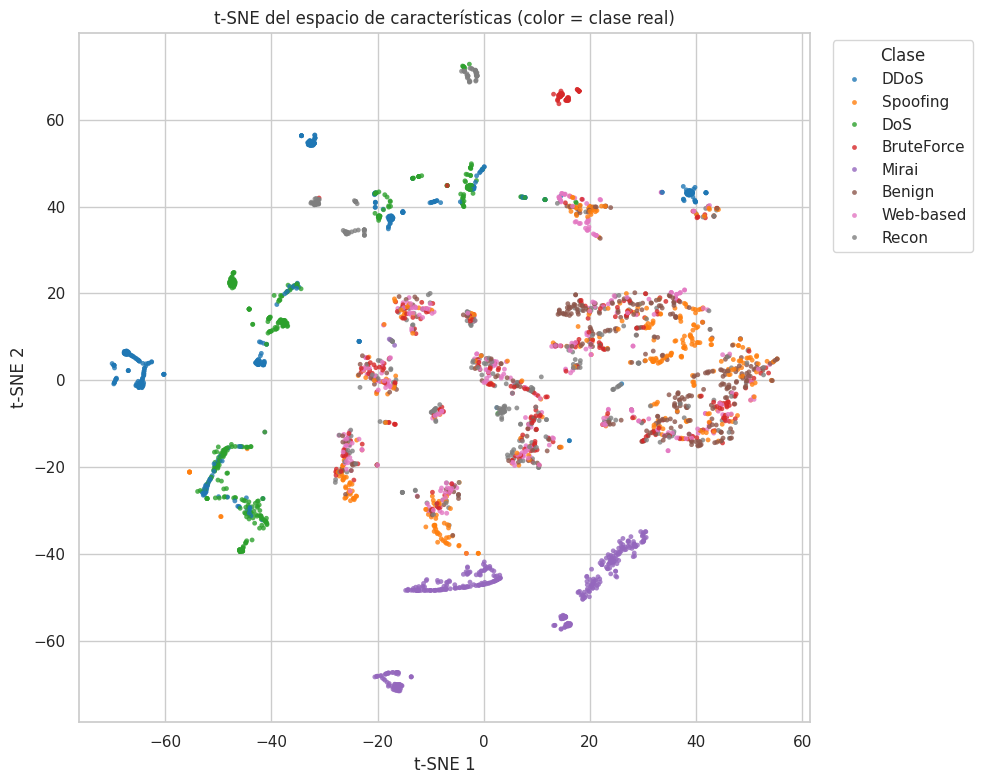

In [33]:
prep = Pipeline(best_rf.steps[:-1])           # imputer + scaler + selector ya ajustados con train
X_s, _, y_s, _ = train_test_split(X_train, y_train, train_size=min(3000, len(X_train) - 1),
                                  stratify=y_train, random_state=RANDOM_STATE)
emb = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(prep.transform(X_s))

fig, ax = plt.subplots(figsize=(10, 8))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_s.values, palette="tab10", s=12, alpha=.8, ax=ax, linewidth=0)
ax.set_title("t-SNE del espacio de características (color = clase real)")
ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2"); ax.legend(title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

**Interpretación del gráfico t-SNE:**

En la visualización generada por t-SNE, la clase Mirai forma agrupaciones (*clusters*) sumamente compactas y claramente separadas del resto. Los ataques DDoS y DoS también definen regiones propias, aunque se posicionan muy cerca entre sí, lo cual es esperable debido a que ambos corresponden a ataques de inundación de tráfico.

Por el contrario, las clases Benign, Recon, Spoofing, Web-based y BruteForce aparecen mezcladas en una amplia región central sin fronteras de separación evidentes. Este comportamiento visual concuerda con la matriz de confusión analizada previamente: las clases que se superponen en el espacio proyectado por t-SNE son las mismas que el modelo confunde con mayor frecuencia, mientras que las clases que se aíslan por completo son aquellas que se clasifican casi sin errores.

## 11. Conclusiones

En este proyecto se construyó y comparó un clasificador de tráfico de red IoT sobre el dataset CICIoT2023 [3], agrupando las 34 etiquetas originales (33 ataques y el tráfico benigno) en ocho clases principales: Benign, DDoS, DoS, Mirai, Recon, Spoofing, BruteForce y Web-based. Dado que el dataset completo consta de millones de registros y está fuertemente dominado por la clase DDoS, se trabajó con una muestra de un máximo de 2,500 registros por clase, lo que garantizó que las clases minoritarias contaran con suficientes ejemplos para las etapas de entrenamiento y evaluación.

**Preparación de los datos:** El análisis exploratorio de datos (EDA) permitió detectar siete columnas constantes (Drate, ece_flag_number, cwr_flag_number, Telnet, SMTP, IRC y DHCP), 147 filas duplicadas, valores infinitos y nueve pares de variables con una correlación superior a 0.95 (por ejemplo, Rate y Srate resultaron ser idénticas). Tras eliminar las variables constantes, los registros duplicados y una característica de cada par redundante, el modelado final se llevó a cabo con 19,503 registros y 32 características. Se observó también que variables como `Header_Length`, `Covariance`, `Rate` y `flow_duration` presentaban valores extremos; estos no se eliminaron puesto que forman parte de la naturaleza de los ataques informáticos, y su impacto se controló mediante la estandarización dentro del pipeline. Al tratarse de datos tabulares estructurados, no fue necesario implementar técnicas de extracción de características (*feature extraction*).

**Pipelines y optimización:** Ambos modelos se implementaron utilizando la estructura de `Pipeline` de scikit-learn [5] (imputación por la mediana → escalado estándar → selección de características tipo filtro → clasificador), lo cual previene de manera absoluta la fuga de información (*data leakage*) entre las particiones de validación cruzada. La optimización mediante validación cruzada estratificada repetida (5 folds × 2 repeticiones) determinó que los mejores parámetros para Random Forest [4] eran 300 árboles, sin límite de profundidad máxima y utilizando las 32 variables, logrando un F1-macro de 0.880. La Regresión Logística obtuvo su mejor resultado con un parámetro de regularización `C = 100` y las 32 variables, con un F1-macro de 0.648. En ambos casos, el filtro de selección conservó el total de las variables, confirmando que la limpieza previa en el EDA ya había depurado la información redundante.

**Comparación de técnicas:** La evaluación estadística mediante validación cruzada repetida (10 folds × 10 repeticiones) reflejó un F1-macro promedio de 0.881 para Random Forest frente a un 0.648 para la Regresión Logística. Tanto la prueba de Wilcoxon como la prueba t pareada corregida de Nadeau-Bengio [6] rechazaron la hipótesis nula de igualdad (p < 0.001), confirmando una diferencia estadísticamente significativa de 0.23 puntos a favor de Random Forest. Las curvas de validación y aprendizaje revelan que la Regresión Logística sufre de subajuste (*underfitting*), pues su estructura lineal le impide trazar fronteras de decisión complejas para datos que no son linealmente separables, estancándose en un F1-macro de ≈0.65 independientemente del volumen de datos. En contraposición, Random Forest modela eficazmente las interacciones no lineales y su rendimiento continúa incrementándose a medida que se aumenta el tamaño de la muestra.

**Desempeño por clase:** En el conjunto de prueba (test), Random Forest obtuvo un F1-macro de 0.890, un valor coherente con la validación, lo que demuestra una robusta capacidad de generalización. El modelo clasifica de manera casi perfecta los ataques de denegación de servicio (DDoS y DoS) y Mirai (F1 ≥ 0.99). Sin embargo, los errores de clasificación se concentran en Recon, Spoofing, BruteForce y Web-based, que representan ataques de bajo volumen de tráfico que se asemejan estrechamente al tráfico legítimo y entre sí. La proyección t-SNE [8] confirmó visualmente esta situación, mostrando agrupaciones claras para Mirai, DDoS y DoS, mientras que las categorías de bajo volumen aparecieron dispersas y mezcladas con el tráfico benigno.

**Limitaciones y trabajo futuro:** Los resultados se obtuvieron a partir de una muestra balanceada artificialmente; en un entorno real con un tráfico dominado casi en su totalidad por DDoS, las métricas globales podrían verse afectadas. Asimismo, el alto costo computacional requerido para realizar la validación cruzada repetida en la plataforma Colab limitó la exploración de un espacio de búsqueda de parámetros más amplio. Como trabajo futuro, se plantea expandir el tamaño de la muestra, emplear transformaciones matemáticas o características polinomiales para reducir el subajuste de los modelos lineales, y evaluar algoritmos avanzados como Gradient Boosting (XGBoost, LightGBM) o redes neuronales profundas para mejorar la discriminación de los ataques de bajo volumen.

En conclusión, Random Forest demostró ser una técnica altamente efectiva para la clasificación de tráfico y detección de amenazas en entornos IoT utilizando el dataset CICIoT2023, superando de manera categórica y con respaldo estadístico a la Regresión Logística.

## Uso de IA (prompts)

Prompt usado con Claude (Anthropic):

> "DEBEMOS REALIZAR TODO ESTO PARA UN DATASET PRESENTE EN MI DRIVE VAMOS A REALIZARLO PASO A PASO SOLO NECESITO TU AYUDA PARA LA CREACION DE CODIGO NO PARA LA PARTE DE ANALISIS Y DISCUSION" — junto con la captura de la rúbrica del proyecto (EDA, feature selection tipo filter, pipelines de sklearn, optimización de hiperparámetros con repeated k-fold CV y gráficas de validación y aprendizaje, comparación estadística de 2 técnicas con Wilcoxon / t-test y repeated k-fold, t-SNE) y el dataset CICIoT2023 (train/validation/test en CSV, también disponible en Kaggle como `himadri07/ciciot2023`), del que se tomó una muestra de 2,500 registros por clase.

Prompt usado con GEMINI:

> "REVISA LA ORTOGRAFÍA DE TODO EL DOCUMENTO"


## 12. Referencias (formato IEEE)

[1] IoT Analytics, “State of IoT 2025: Number of connected IoT devices growing 14% to 21.1 billion globally,” Oct. 28, 2025. [Online]. Available: https://iot-analytics.com/number-connected-iot-devices/

[2] M. Antonakakis et al., “Understanding the Mirai botnet,” in Proc. 26th USENIX Security Symp., Vancouver, BC, Canada, 2017, pp. 1093–1110.

[3] E. C. P. Neto, S. Dadkhah, R. Ferreira, A. Zohourian, R. Lu, and A. A. Ghorbani, “CICIoT2023: A real-time dataset and benchmark for large-scale attacks in IoT environment,” Sensors, vol. 23, no. 13, p. 5941, 2023, doi: 10.3390/s23135941.

[4] L. Breiman, “Random forests,” Mach. Learn., vol. 45, no. 1, pp. 5–32, 2001.

[5] F. Pedregosa et al., “Scikit-learn: Machine learning in Python,” J. Mach. Learn. Res., vol. 12, pp. 2825–2830, 2011.

[6] C. Nadeau and Y. Bengio, “Inference for the generalization error,” Mach. Learn., vol. 52, no. 3, pp. 239–281, 2003.

[7] J. Demšar, “Statistical comparisons of classifiers over multiple data sets,” J. Mach. Learn. Res., vol. 7, pp. 1–30, 2006.

[8] L. van der Maaten and G. Hinton, “Visualizing data using t-SNE,” J. Mach. Learn. Res., vol. 9, pp. 2579–2605, 2008.

[9] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, “Optuna: A next-generation hyperparameter optimization framework,” in Proc. 25th ACM SIGKDD, 2019, pp. 2623–2631.

[10] Anthropic, “Claude,” asistente de IA utilizado para el código y la redacción de este notebook, 2026.